In [3]:
import seaborn as sns
import pandas as pd

# Titanic veri setini seaborn kütüphanesin içinden yüklenir.
df = sns.load_dataset("titanic")

# Veri setinin yapısını incelemek için ilk 5 satır görüntülenir.
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Tüm sütunların veri tiplerini görüntülüyoruz
print("Veri Tipleri")
print(df.dtypes)

# Kategorik değişkenleri tespit ediliyor. (metin, kategori ve mantıksal tipler)
categorical_cols = df.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

# Sayısal değişkenleri tespit ediliyor. (tamsayı ve ondalıklı sayı tipleri)
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# ve sonuçların ekrana yazılması.
print("\nKategorik Değişkenler:", categorical_cols)
print("Sayısal Değişkenler:", numerical_cols)

Veri Tipleri
survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class          category
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object

Kategorik Değişkenler: ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
Sayısal Değişkenler: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']


In [5]:
# Veri setindeki her bir sütunun eksik (null/NaN) değer sayılarını ve oranlarını tespit ediyoruz
missing_count = df.isnull().sum()
missing_ratio = (df.isnull().sum() / len(df)) * 100

# Sadece eksik veri içeren sütunları filtreleyip tablo olarak gösteriyoruz
missing_df = pd.DataFrame({
    'Eksik Değer Sayısı': missing_count[missing_count > 0],
    'Eksiklik Oranı (%)': missing_ratio[missing_ratio > 0].round(2)
})

print(missing_df)

             Eksik Değer Sayısı  Eksiklik Oranı (%)
age                         177               19.87
embarked                      2                0.22
deck                        688               77.22
embark_town                   2                0.22


In [6]:
# 1. Sayısal değişken (age): Aykırı değerlere karşı dayanıklı olması için medyan ile dolduruyoruz
age_median = df['age'].median()
df['age'] = df['age'].fillna(age_median)

# 2. Kategorik değişkenler (embarked ve embark_town): En çok tekrar eden mod değeri ile dolduruyoruz
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])

# 3. Kategorik değişken (deck): Yönergeye uygun olarak en sık görülen kategori (mod) ile dolduruyoruz
df['deck'] = df['deck'].fillna(df['deck'].mode()[0])

# Doldurma sonrası veri setinde eksik değer kalıp kalmadığını teyit ediyoruz
print("Kalan Toplam Eksik Değer Sayısı:", df.isnull().sum().sum())

Kalan Toplam Eksik Değer Sayısı: 0


In [7]:
from sklearn.preprocessing import StandardScaler

# StandardScaler nesnesini oluşturuyoruz
scaler = StandardScaler()

# 'fare' sayısal değişkenine Z-score standardizasyonu uyguluyoruz
df['fare_zscore'] = scaler.fit_transform(df[['fare']])

# Dönüşüm öncesi ve sonrası değerleri karşılaştırıyoruz
print("--- Z-Score Standardizasyonu Sonrası İlk 5 Satır ---")
print(df[['fare', 'fare_zscore']].head())

# İstatistiksel doğrulama
print("\nStandardize Değerlerin Ortalaması (Hedef ~0):", round(df['fare_zscore'].mean(), 2))
print("Standardize Değerlerin Standart Sapması (Hedef 1):", round(df['fare_zscore'].std(), 2))

--- Z-Score Standardizasyonu Sonrası İlk 5 Satır ---
      fare  fare_zscore
0   7.2500    -0.502445
1  71.2833     0.786845
2   7.9250    -0.488854
3  53.1000     0.420730
4   8.0500    -0.486337

Standardize Değerlerin Ortalaması (Hedef ~0): 0.0
Standardize Değerlerin Standart Sapması (Hedef 1): 1.0


In [8]:
#5.
from sklearn.preprocessing import MinMaxScaler

# MinMaxScaler nesnesini tanımlıyoruz
min_max_scaler = MinMaxScaler()

# 'age' (yaş) sayısal sütununa Min-Max normalizasyonu uyguluyoruz
df['age_minmax'] = min_max_scaler.fit_transform(df[['age']])

# Dönüşüm öncesi ve sonrası ilk 5 değeri karşılaştırıyoruz
print("--- Min-Max Normalizasyonu Sonrası İlk 5 Satır ---")
print(df[['age', 'age_minmax']].head())

# Sınır değerlerin [0, 1] aralığında olduğunu teyit ediyoruz
print("\nNormalize Edilmiş Yaşın En Küçük Değeri (Hedef 0.0):", df['age_minmax'].min())
print("Normalize Edilmiş Yaşın En Büyük Değeri (Hedef 1.0):", df['age_minmax'].max())

--- Min-Max Normalizasyonu Sonrası İlk 5 Satır ---
    age  age_minmax
0  22.0    0.271174
1  38.0    0.472229
2  26.0    0.321438
3  35.0    0.434531
4  35.0    0.434531

Normalize Edilmiş Yaşın En Küçük Değeri (Hedef 0.0): 0.0
Normalize Edilmiş Yaşın En Büyük Değeri (Hedef 1.0): 1.0


In [9]:
#5 
# İkinci örnek: 'sibsp' (gemideki kardeş/eş sayısı) değişkenine Min-Max normalizasyonu uyguluyoruz
df['sibsp_minmax'] = min_max_scaler.fit_transform(df[['sibsp']])

# İlk 5 satırı inceleyelim
print("--- İkinci Örnek: 'sibsp' Min-Max Normalizasyonu İlk 5 Satır ---")
print(df[['sibsp', 'sibsp_minmax']].head())

# Sınır değer kontrolleri
print("\nNormalize Edilmiş SibSp Min Değeri:", df['sibsp_minmax'].min())
print("Normalize Edilmiş SibSp Max Değeri:", df['sibsp_minmax'].max())


--- İkinci Örnek: 'sibsp' Min-Max Normalizasyonu İlk 5 Satır ---
   sibsp  sibsp_minmax
0      1         0.125
1      1         0.125
2      0         0.000
3      1         0.125
4      0         0.000

Normalize Edilmiş SibSp Min Değeri: 0.0
Normalize Edilmiş SibSp Max Değeri: 1.0


In [12]:
#6
from sklearn.preprocessing import LabelEncoder

# 1. Yöntem: Label Encoding ('sex' ikili kategorik değişkeni için)
le = LabelEncoder()
df['sex_encoded'] = le.fit_transform(df['sex'])

# Label Encoding sonuçlarını ve eşleşmeleri inceliyoruz
print("--- 1. Label Encoding: 'sex' Değişkeni ---")
print(df[['sex', 'sex_encoded']].head())
print("Sınıf Eşleşmeleri:", dict(zip(le.classes_, le.transform(le.classes_))))

# 2. Yöntem: One-Hot Encoding ('embarked' çok sınıflı nominal değişkeni için)
embarked_dummies = pd.get_dummies(df['embarked'], prefix='embarked', dtype=int)
df = pd.concat([df, embarked_dummies], axis=1)

# One-Hot Encoding sonucunda oluşan kukla (dummy) sütunları inceliyoruz
print("\n--- 2. One-Hot Encoding: 'embarked' Değişkeni ---")
print(df[['embarked', 'embarked_C', 'embarked_Q', 'embarked_S']].head())

--- 1. Label Encoding: 'sex' Değişkeni ---
      sex  sex_encoded
0    male            1
1  female            0
2  female            0
3  female            0
4    male            1
Sınıf Eşleşmeleri: {'female': 0, 'male': 1}

--- 2. One-Hot Encoding: 'embarked' Değişkeni ---
  embarked  embarked_C  embarked_C  embarked_Q  embarked_Q  embarked_S  \
0        S           0           0           0           0           1   
1        C           1           1           0           0           0   
2        S           0           0           0           0           1   
3        S           0           0           0           0           1   
4        S           0           0           0           0           1   

   embarked_S  
0           1  
1           0  
2           1  
3           1  
4           1  


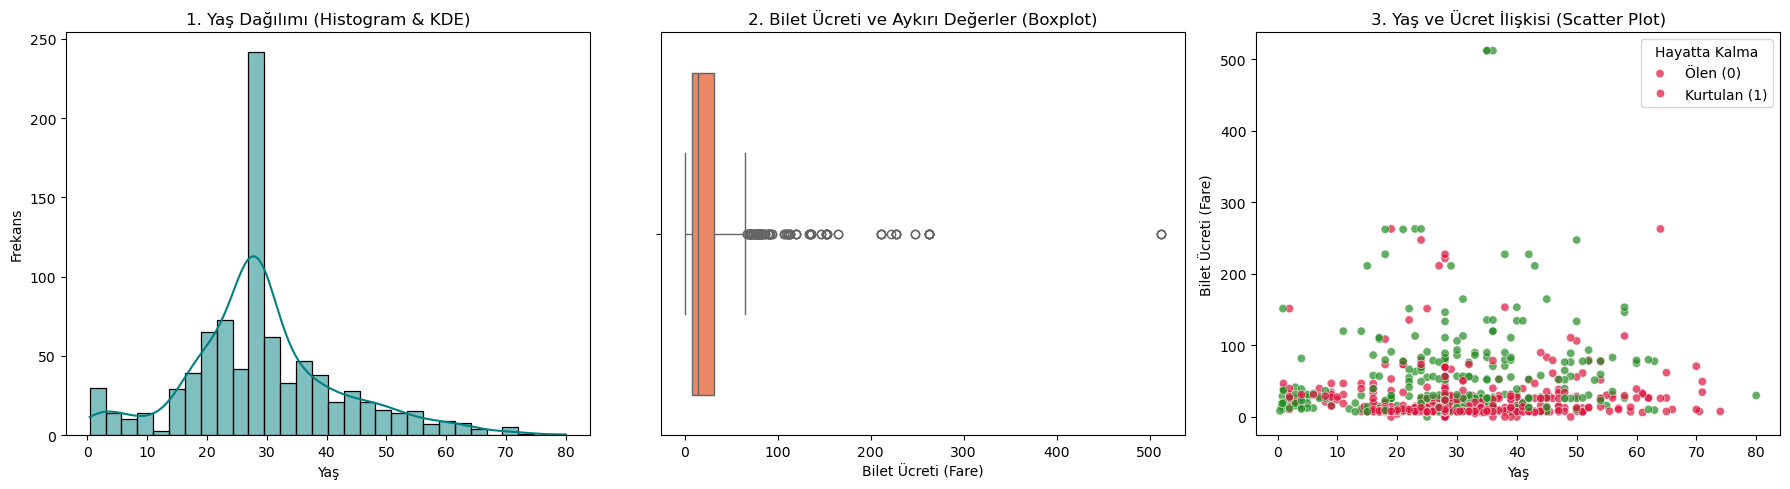

In [14]:
#7
import matplotlib.pyplot as plt
import seaborn as sns

# Görselleştirme alanını tanımlıyoruz (1 satır, 3 sütun)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Görselleştirme: 'age' değişkeni için Histogram ve KDE
sns.histplot(df['age'], kde=True, color='teal', ax=axes[0])
axes[0].set_title('1. Yaş Dağılımı (Histogram & KDE)', fontsize=12)
axes[0].set_xlabel('Yaş')
axes[0].set_ylabel('Frekans')

# 2. Görselleştirme: 'fare' değişkeni için Kutu Grafiği (Boxplot)
sns.boxplot(x=df['fare'], color='coral', ax=axes[1])
axes[1].set_title('2. Bilet Ücreti ve Aykırı Değerler (Boxplot)', fontsize=12)
axes[1].set_xlabel('Bilet Ücreti (Fare)')

# 3. Görselleştirme: 'age' ve 'fare' arasındaki ilişki için Dağılım Grafiği (Scatter Plot)
# 'survived' değişkeni hue parametresi olarak eklenerek hayatta kalma durumu da görselleştirilmiştir
sns.scatterplot(data=df, x='age', y='fare', hue='survived', palette={0: 'crimson', 1: 'forestgreen'}, alpha=0.7, ax=axes[2])
axes[2].set_title('3. Yaş ve Ücret İlişkisi (Scatter Plot)', fontsize=12)
axes[2].set_xlabel('Yaş')
axes[2].set_ylabel('Bilet Ücreti (Fare)')
axes[2].legend(title='Hayatta Kalma', labels=['Ölen (0)', 'Kurtulan (1)'])

plt.tight_layout()
plt.show()